# Assignment 62 — Week 7, Day 1
## Topic: Deep Learning — Text Analysis

**Objective:** Complete the text-analysis exercise.

**Reference:** https://medium.com/towards-artificial-intelligence/natural-language-processing-nlp-with-python-tutorial-for-beginners-1f54e610a1a0

Text analysis turns text into numbers and insights. Building on the processing steps from the Towards AI NLP tutorial (tokenising, cleaning, lemmatising), this notebook analyses text by:

1. Word frequencies and frequency plots
2. Collocations: words that often appear together (bigrams)
3. Bag of words and TF-IDF features
4. Sentiment analysis with VADER
5. Text classification of movie reviews with scikit-learn

**Requirements:** `pip install nltk scikit-learn`, then the NLTK data downloaded in the first cell.

**Download the NLTK data**

In [1]:
import nltk

for package in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4", "vader_lexicon", "movie_reviews"]:
    nltk.download(package, quiet=True)

print("NLTK", nltk.__version__, "ready")

NLTK 3.10.3 ready


**Explanation:** The tokeniser, stop words, WordNet, the VADER sentiment lexicon and the movie review corpus are downloaded once.

## 1. Word frequencies

**Clean the text**

In [2]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

article = """Machine learning is changing how we work. Machine learning models learn patterns from data, and the data must be clean. Good data gives good models, while bad data gives bad models. Deep learning is a part of machine learning that uses neural networks. Neural networks learn from large amounts of data. Many companies now use machine learning to understand customers, predict sales and detect fraud. Learning these skills is useful for students who want to work with data."""

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

tokens = word_tokenize(article.lower())
clean = [lemmatizer.lemmatize(w) for w in tokens if w.isalpha() and w not in stop_words]

print("Tokens:", len(tokens), "| after cleaning:", len(clean))
print(clean[:20])

Tokens: 88 | after cleaning: 55
['machine', 'learning', 'changing', 'work', 'machine', 'learning', 'model', 'learn', 'pattern', 'data', 'data', 'must', 'clean', 'good', 'data', 'give', 'good', 'model', 'bad', 'data']


**Explanation:** The text is lower-cased, tokenised, stripped of punctuation and stop words, and lemmatised, so 'models' and 'model' count as the same word.

**Frequency distribution**

In [3]:
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

article = """Machine learning is changing how we work. Machine learning models learn patterns from data, and the data must be clean. Good data gives good models, while bad data gives bad models. Deep learning is a part of machine learning that uses neural networks. Neural networks learn from large amounts of data. Many companies now use machine learning to understand customers, predict sales and detect fraud. Learning these skills is useful for students who want to work with data."""
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()
clean = [lemmatizer.lemmatize(w) for w in word_tokenize(article.lower()) if w.isalpha() and w not in stop_words]

fdist = nltk.FreqDist(clean)
print(fdist.most_common(10))
print("Lexical diversity:", round(len(set(clean)) / len(clean), 2))

[('learning', 6), ('data', 6), ('machine', 4), ('model', 3), ('work', 2), ('learn', 2), ('good', 2), ('give', 2), ('bad', 2), ('neural', 2)]
Lexical diversity: 0.6


**Explanation:** FreqDist counts every word. The most common words (data, learning, machine, model) show what the text is about. Lexical diversity is the share of unique words; a lower value means more repetition.

**Plot the most common words**

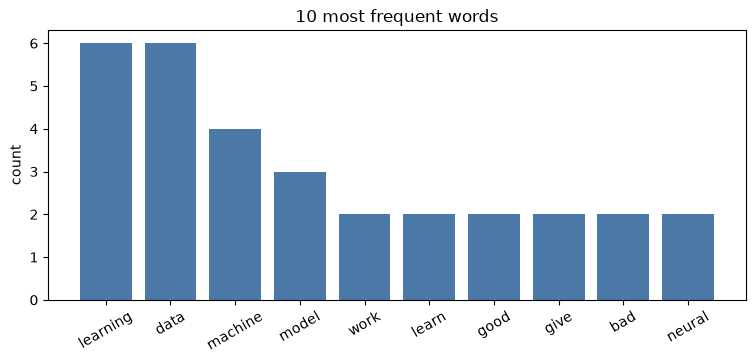

In [4]:
import nltk
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

article = """Machine learning is changing how we work. Machine learning models learn patterns from data, and the data must be clean. Good data gives good models, while bad data gives bad models. Deep learning is a part of machine learning that uses neural networks. Neural networks learn from large amounts of data. Many companies now use machine learning to understand customers, predict sales and detect fraud. Learning these skills is useful for students who want to work with data."""
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()
clean = [lemmatizer.lemmatize(w) for w in word_tokenize(article.lower()) if w.isalpha() and w not in stop_words]

words, counts = zip(*nltk.FreqDist(clean).most_common(10))
plt.figure(figsize=(9, 3.5))
plt.bar(words, counts, color="#4C78A8")
plt.title("10 most frequent words")
plt.ylabel("count")
plt.xticks(rotation=30)
plt.show()

**Explanation:** A bar chart makes the frequency distribution easy to read at a glance.

## 2. Collocations

**Find words that appear together**

In [5]:
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.collocations import BigramCollocationFinder, BigramAssocMeasures

article = """Machine learning is changing how we work. Machine learning models learn patterns from data, and the data must be clean. Good data gives good models, while bad data gives bad models. Deep learning is a part of machine learning that uses neural networks. Neural networks learn from large amounts of data. Many companies now use machine learning to understand customers, predict sales and detect fraud. Learning these skills is useful for students who want to work with data."""
stop_words = set(stopwords.words("english"))
words = [w for w in word_tokenize(article.lower()) if w.isalpha() and w not in stop_words]

print("Most common bigrams:", nltk.FreqDist(nltk.bigrams(words)).most_common(5))

finder = BigramCollocationFinder.from_words(words)
finder.apply_freq_filter(2)
print("Collocations:", finder.nbest(BigramAssocMeasures.likelihood_ratio, 4))

Most common bigrams: [(('machine', 'learning'), 4), (('data', 'gives'), 2), (('neural', 'networks'), 2), (('learning', 'changing'), 1), (('changing', 'work'), 1)]
Collocations: [('machine', 'learning'), ('neural', 'networks'), ('data', 'gives')]


**Explanation:** Bigrams are pairs of neighbouring words. Collocations are pairs that appear together more often than chance, such as 'machine learning' and 'neural networks', which act as single terms.

## 3. Bag of words and TF-IDF

**Diagram:** A bag-of-words table: one row per document, one column per vocabulary word.

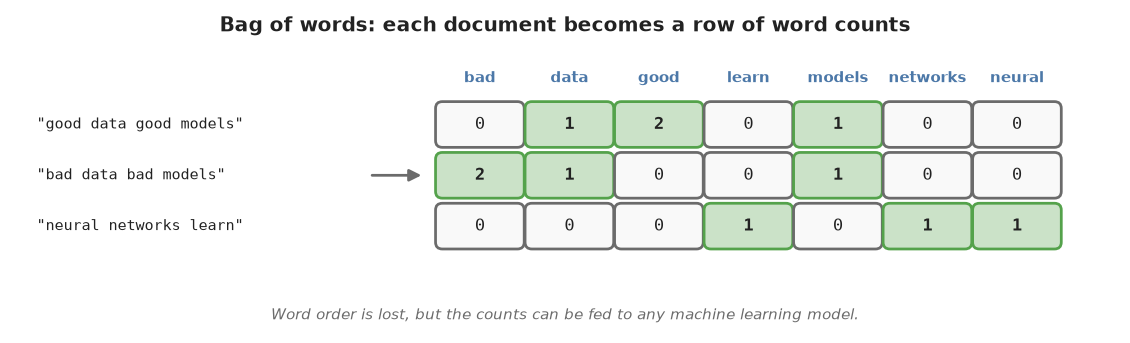

**Bag of words with CountVectorizer**

In [6]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

documents = ["good data good models", "bad data bad models", "neural networks learn"]

vectorizer = CountVectorizer()
X = vectorizer.fit_transform(documents)

print(pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out(), index=["doc1", "doc2", "doc3"]))

      bad  data  good  learn  models  networks  neural
doc1    0     1     2      0       1         0       0
doc2    2     1     0      0       1         0       0
doc3    0     0     0      1       0         1       1


**Explanation:** CountVectorizer builds a vocabulary of all words and counts each word in each document. The result is a numeric table that machine learning models can use.

**Diagram:** TF-IDF weighs each word count by how rare the word is across documents.

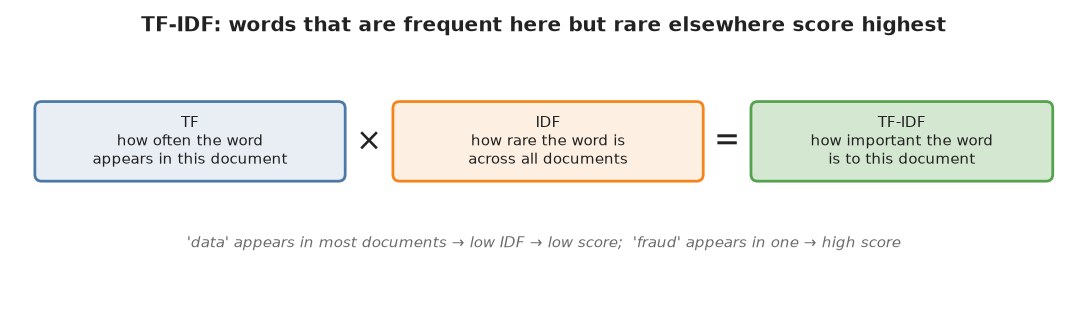

**TF-IDF with TfidfVectorizer**

In [7]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

documents = [
    "machine learning models learn from data",
    "clean data gives good models",
    "companies use machine learning to detect fraud",
]

tfidf = TfidfVectorizer()
X = tfidf.fit_transform(documents)

df = pd.DataFrame(X.toarray(), columns=tfidf.get_feature_names_out()).round(2)
print(df.T)

              0     1     2
clean      0.00  0.49  0.00
companies  0.00  0.00  0.40
data       0.37  0.37  0.00
detect     0.00  0.00  0.40
fraud      0.00  0.00  0.40
from       0.48  0.00  0.00
gives      0.00  0.49  0.00
good       0.00  0.49  0.00
learn      0.48  0.00  0.00
learning   0.37  0.00  0.31
machine    0.37  0.00  0.31
models     0.37  0.37  0.00
to         0.00  0.00  0.40
use        0.00  0.00  0.40


**Explanation:** TF-IDF gives words like 'fraud' and 'clean', which appear in only one document, higher weights than 'data' and 'models', which appear in several. It highlights the words that make each document distinctive.

## 4. Sentiment analysis

**Diagram:** How VADER's compound score is usually read.

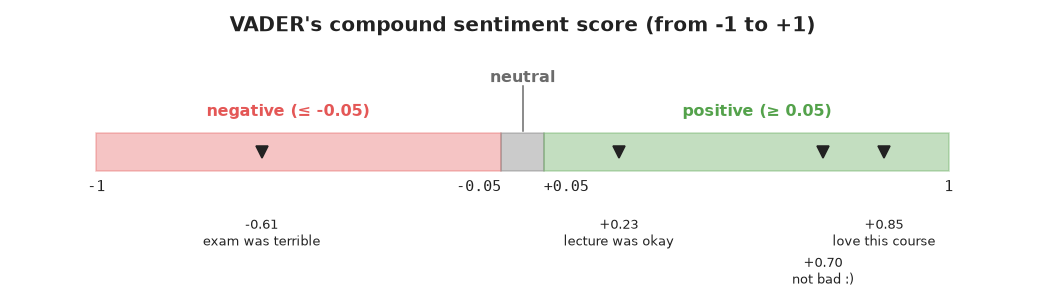

**Sentiment scores with VADER**

In [8]:
from nltk.sentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

sentences = [
    "I love this course, the teachers are excellent!",
    "The lecture was okay.",
    "The exam was terrible and the instructions were confusing.",
    "Not bad at all :)",
]

for s in sentences:
    scores = sia.polarity_scores(s)
    label = "positive" if scores["compound"] >= 0.05 else "negative" if scores["compound"] <= -0.05 else "neutral"
    print(f"{scores['compound']:+.3f} {label:9} {s}")

+0.848 positive  I love this course, the teachers are excellent!
+0.226 positive  The lecture was okay.
-0.612 negative  The exam was terrible and the instructions were confusing.
+0.705 positive  Not bad at all :)


**Explanation:** VADER is a rule-based sentiment analyser built for short, informal text. It gives negative, neutral and positive scores plus a compound score from -1 to 1, and it understands negation ('not bad'), capitals and emoticons.

## 5. Text classification

**Classify movie reviews with TF-IDF and Naive Bayes**

In [9]:
from nltk.corpus import movie_reviews
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

texts = [movie_reviews.raw(fid) for fid in movie_reviews.fileids()]
labels = [movie_reviews.categories(fid)[0] for fid in movie_reviews.fileids()]

X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.2, random_state=42, stratify=labels)

vectorizer = TfidfVectorizer(stop_words="english", max_features=5000)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

model = MultinomialNB().fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred))

Accuracy: 0.807
              precision    recall  f1-score   support

         neg       0.79      0.83      0.81       200
         pos       0.82      0.79      0.80       200

    accuracy                           0.81       400
   macro avg       0.81      0.81      0.81       400
weighted avg       0.81      0.81      0.81       400



**Explanation:** The 2000 movie reviews are turned into TF-IDF features and a Multinomial Naive Bayes model is trained to tell positive from negative reviews. It is tested on 400 reviews it has not seen.

**Words that most indicate each class**

In [10]:
import numpy as np
from nltk.corpus import movie_reviews
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

texts = [movie_reviews.raw(fid) for fid in movie_reviews.fileids()]
labels = [movie_reviews.categories(fid)[0] for fid in movie_reviews.fileids()]
vectorizer = TfidfVectorizer(stop_words="english", max_features=5000)
X = vectorizer.fit_transform(texts)
model = MultinomialNB().fit(X, labels)

words = vectorizer.get_feature_names_out()
log_ratio = model.feature_log_prob_[1] - model.feature_log_prob_[0]   # pos vs neg
print("Most positive words:", list(words[np.argsort(log_ratio)[-10:][::-1]]))
print("Most negative words:", list(words[np.argsort(log_ratio)[:10]]))

Most positive words: ['mulan', 'truman', 'shrek', 'lebowski', 'damon', 'flynt', 'argento', 'outstanding', 'guido', 'bulworth']
Most negative words: ['seagal', 'worst', 'godzilla', 'waste', 'lame', 'stupid', 'boring', 'jolie', 'awful', 'schumacher']


**Explanation:** Comparing the learned word probabilities for the two classes shows which words push a review towards positive or negative. Opinion words such as 'outstanding', 'worst', 'boring' and 'awful' appear, but so do names of well-liked or disliked films and actors (for example 'mulan' and 'seagal'), because the model only learns which words co-occur with each label in this data.

## Observation

- Cleaning (lower-casing, removing stop words and punctuation, lemmatising) makes word counts meaningful.
- Frequency distributions show the main topics of a text, and collocations such as 'machine learning' reveal multi-word terms.
- Bag of words turns documents into word counts; TF-IDF weights them so distinctive words stand out.
- VADER gives quick sentiment scores for short text and handles negation and emoticons.
- TF-IDF features with a Naive Bayes classifier sort movie reviews into positive and negative with roughly 80% accuracy, and the learned weights show which words drive each decision.

## Conclusion

Text analysis converts language into numbers that can be counted, compared and modelled. These techniques power search engines, review analysis, spam filters and many other real-world NLP applications.